# AlexNet

<img src="images/alexnet.svg" alt="Схема AlexNet" height="700">

Исходная AlexNet рассчитана на изображения `224×224`, а изображения CIFAR-10 имеют размер `32×32`. Поэтому адаптируем архитектуру:

- **Вход:** `3×224×224` → `3×32×32`.
- **Первая свёртка:** 96 фильтров `11×11`, `stride=4` → 96 фильтров `3×3`, `stride=1`, `padding=1`.
- **Max pooling после 1-й, 2-й и 5-й свёрток:** окно `3×3`, `stride=2` → окно `3×3`, `stride=2`, `padding=1`. После трёх pooling размер карт будет `32 → 16 → 8 → 4`.
- **Вход первого полносвязного слоя:** `256×6×6 = 9216` признаков → `256×4×4 = 4096` признаков.
- **Первый полносвязный слой:** `9216 → 4096` → `4096 → 512`.
- **Второй полносвязный слой:** `4096 → 4096` → `512 → 256`.
- **Выходной слой:** `4096 → 1000` → `256 → 10`.

Во 2-й–5-й свёртках сохраняем число фильтров и размеры ядер. Также сохраняем `ReLU`, LRN после первых двух свёрток, `groups=2` во 2-й, 4-й и 5-й свёртках и `Dropout(0.5)` в двух скрытых полносвязных блоках. \
Упразднён параметр group=2 за ненадобностью распараллеливания обучения на 2 машины, как было в оригинале.

In [ ]:
import torch.nn as nn
import torch
import pandas as pd
from typing import Callable
from torch.utils.data import TensorDataset
import sys
sys.path.append("../utils")
from data_utils import images_to_tensor, train_dataset_split, create_dataloader

In [ ]:
SEED = 52

torch.manual_seed(SEED)

## Работа с данными

In [ ]:
X_train, y_train = images_to_tensor(
    "../data/train",
    "../data/trainLabels.csv",
)

Создаём Dataset который умеет выдавать по одному значению, он используется в DataLoader

In [11]:
ds_train = TensorDataset(X_train, y_train)

Разобъём train на tain и val с помощью `train_dataset_split` из из data_utils

In [ ]:
ds_train, ds_val = train_dataset_split(ds_train, train_size=0.8, random_seed=SEED)

In [ ]:
BATCH_SIZE = 256

Создаём DataLoader для train и val, которые будут выдавать наши пары (картинка, класс) батчами  при обучении

In [ ]:
dl_train = create_dataloader(ds_train, BATCH_SIZE, shuffle=True, random_seed=SEED)
dl_val = create_dataloader(ds_val, BATCH_SIZE, shuffle=False, random_seed=SEED)

## Создание класса AlexNet

In [ ]:
class AlexNet(nn.Module):
    """Упрощённая адаптация AlexNet для изображений CIFAR-10 размером 32x32."""

    def __init__(
        self,
        in_channels: int = 3,
        output_size: int = 10,
        image_size: tuple[int, int] = (32, 32)
    ):

        super().__init__()

        modules = []
        conv_layers = [96, 256, 384, 384, 256]

        in_ = in_channels # количество входных каналов для свёртки
        for i in range(len(conv_layers)): # цикл добавления свёрточных блоков (смотреть схему)

            # свёртка
            if i == 1:
                modules.append(nn.Conv2d(
                    in_channels=in_,
                    out_channels=conv_layers[i],
                    kernel_size=5,
                    stride=1,
                    padding=2,
                    ))
            else:
                modules.append(nn.Conv2d(
                    in_channels=in_,
                    out_channels=conv_layers[i],
                    kernel_size=3,
                    stride=1,
                    padding=1,
                    ))
            in_ = conv_layers[i]

            modules.append(nn.ReLU()) # слой активации после какждой свёртки

            if i in [0, 1]:
                modules.append(nn.LocalResponseNorm(size=5)) # значение size=5 взято из оригинальной версии

            if i in [0, 1, 4]: # в блоках 1, 2, 5 есть maxpool
                modules.append(nn.MaxPool2d(kernel_size=3, stride=2, padding=1))

        #вычиляем на искусственном примере размер картинки, который получился после всех свёрток
        with torch.no_grad():
            sample = torch.zeros(1, in_channels, *image_size)
            in_features = nn.Sequential(*modules)(sample).flatten(1).shape[1]

        # после всех свёрточных слоёв распрямляем значения в вектор, чтобы подать на вход линейному слою
        modules.append(nn.Flatten())
        # после выпрямления получаем вектор из 4096 чисел

        # 1 линейный слой на 512 нейронов
        modules.append(nn.Linear(in_features, 512))
        modules.append(nn.ReLU())
        modules.append(nn.Dropout(0.5))

        # 2 линейный слой на 256 нейронов
        modules.append(nn.Linear(512, 256))
        modules.append(nn.ReLU())
        modules.append(nn.Dropout(0.5))

        # в конце добавляем выходной слой, дающий предсказания (логиты) для каждого из классов
        modules.append(nn.Linear(256, output_size))

        self.network = nn.Sequential(*modules)

    def forward(self, x):
        return self.network(x)

In [ ]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Устройство: {DEVICE}")

In [ ]:
alexnet = AlexNet(3, 10).to(DEVICE)
loss_func = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(alexnet.parameters(), lr=3e-4)

In [ ]:
import sys
sys.path.append("../utils")
from train_utils import train, test

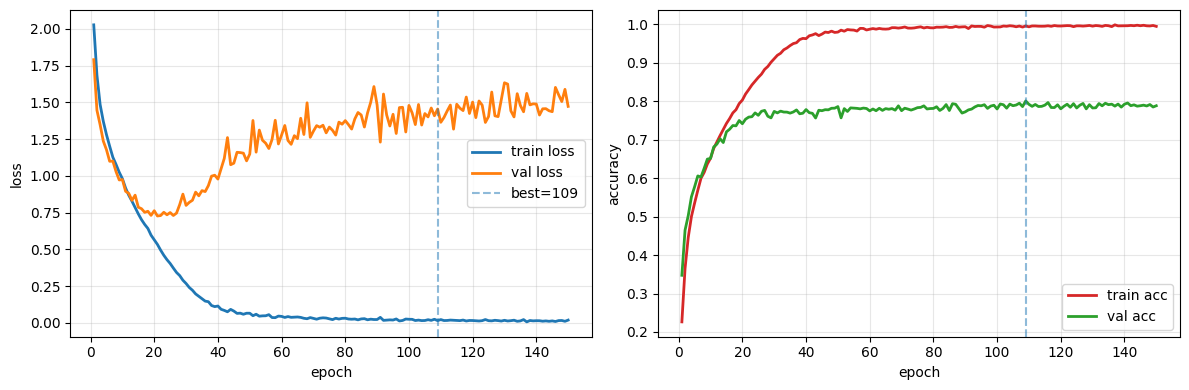

Best epoch = 109, best val_acc = 0.8006


,0
0,0.8006
1,109.0000


In [ ]:
train(alexnet, optimizer, loss_func, dl_train, dl_val, "models/alexnet.pth", DEVICE, EPOCH_COUNT=150)

## Test
Проверим нашу лучшую модель на тестовом множестве картинок

In [ ]:
alexnet_best = AlexNet(3, 10, (32, 32)).to(DEVICE)
alexnet_best.load_state_dict(torch.load('models/alexnet.pth'))
alexnet_best.eval()

In [ ]:
X_test = images_to_tensor(
    "../data/test",
    "../data/sampleSubmission.csv",
    has_labels=False,
)

In [ ]:
dl_test = create_dataloader(X_test, batch_size=BATCH_SIZE, shuffle=False)
class_names = sorted(pd.read_csv("../data/trainLabels.csv")["label"].unique())

In [ ]:
submission = test(
    alexnet_best,
    dl_test,
    class_names,
    "../data/sampleSubmission.csv",
    "alexnet_submission.csv",
    DEVICE,
)

## Итог


В ходе работы была реализована и обучена адаптированная архитектура **AlexNet** для классификации изображений датасета CIFAR-10. Максимальная точность на валидационной выборке составила **80,06 %** и была достигнута на 109-й эпохе.

Полученный результат свидетельствует об эффективности модели при решении задачи классификации цветных изображений. AlexNet, предложенная в 2012 году, стала важным этапом развития глубокого обучения благодаря использованию нескольких свёрточных слоёв, позволяющих извлекать признаки различной сложности. Несмотря на необходимость адаптации исходной архитектуры под небольшой размер изображений CIFAR-10, модель показала хорошие результаты, продемонстрировав способность распознавать объекты из десяти классов.
